In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import json
from req_functions_from_ApproxSP import *
from tqdm import tqdm
from generate_profiles import *
from euclidean import *
from mallows import *
from impartial import *
from all_stable import *
import pandas as pd
import ast
import csv
import pandas as pd

In [10]:
import pandas as pd

df = pd.read_csv("euclidean_mallows_accomplice.csv")

manipulable_df = df[df['self_manipulating_women'] > 0]

summary = manipulable_df.groupby(['phi_m', 'phi_w']).agg(
    manipulable_total=('self_manipulating_women', 'count'),  # number of manipulable instances (denominator)
    total_manipulators=('self_manipulating_women', 'sum')    # total number of manipulators (numerator)
).reset_index()


summary['manipulation_percentage'] = summary['total_manipulators'] / summary['manipulable_total']



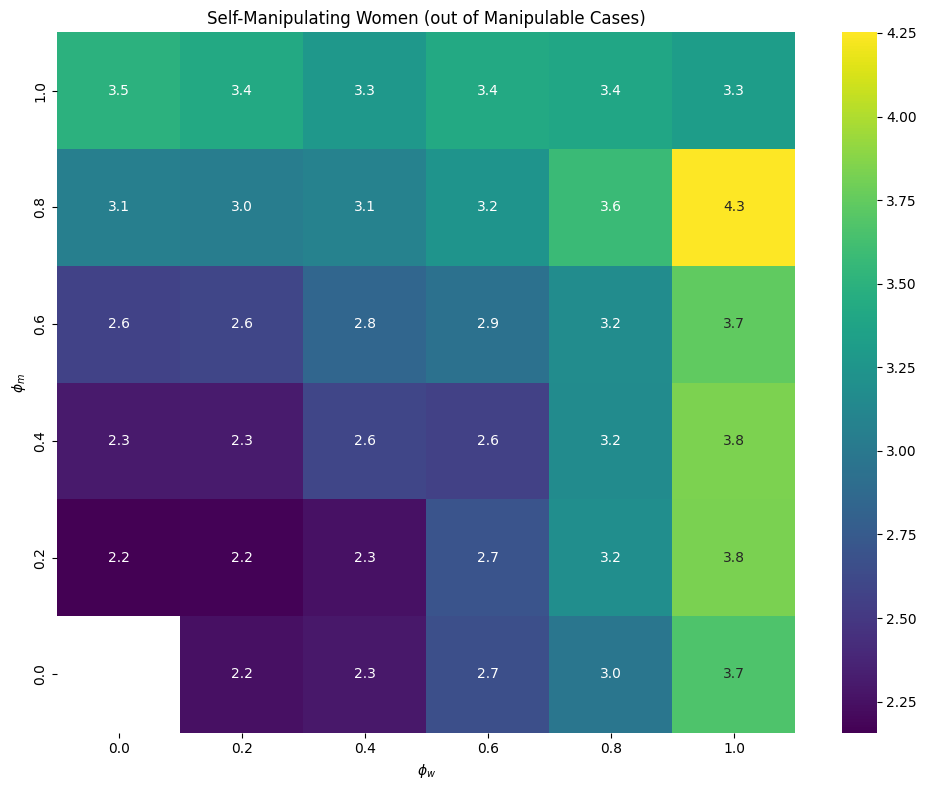

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Pivot for heatmap
heatmap_data = summary.pivot(index='phi_m', columns='phi_w', values='manipulation_percentage')

# Plot
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=True, fmt=".1f", cmap="viridis")

# Invert y-axis (optional)
plt.gca().invert_yaxis()

# Labels
plt.title("Self-Manipulating Women (out of Manipulable Cases)")
plt.xlabel(r'$\phi_w$')
plt.ylabel(r'$\phi_m$')
plt.tight_layout()
plt.show()
